# Занятие 8. Лабораторная работа 3. Сегментация объектов и упаковок (PyTorch)
## Нейросетевые методы обработки изображений

В этом ноутбуке мы:
1. Загрузим подвыборку набора данных Package Segmentation (Ultralytics).
2. Построим бинарные маски сегментации упаковок из разметки контуров.
3. Обучим облегчённую U-Net в PyTorch на задаче «объект/фон».
4. Оценим качество через Dice/IoU.
5. Обсудим (текстово) различия семантической и instance-сегментации на конкретных примерах изображений.

**Набор данных:** Package Segmentation (Ultralytics)
https://docs.ultralytics.com/datasets/segment/package-seg

**Важно:** все примеры рассчитаны на выполнение без графического процессора (GPU).
Используется подвыборка из 80 изображений (обучение) и 20 изображений (проверка).

---
## Шаг 1. Импорт библиотек и настройка окружения

In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageDraw

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cpu')  # задача выполняется без графического процессора
print(f'PyTorch: {torch.__version__}')
print(f'Устройство вычислений: {device}')

PyTorch: 2.12.1+cpu
Устройство вычислений: cpu


---
## Шаг 2. Загрузка набора данных Package Segmentation

### Инструкция по получению данных

1. Набор данных распространяется свободно и скачивается автоматически по
   прямой ссылке, без необходимости регистрации:
   `https://github.com/ultralytics/assets/releases/download/v0.0.0/package-seg.zip`
2. Скачайте и распакуйте архив (около 103 МБ) в папку `./data/package_seg/`.
3. Формат разметки: для каждого изображения имеется текстовый файл с координатами
   многоугольника (в относительных координатах от 0 до 1), охватывающего каждую
   упаковку -- формат, аналогичный формату YOLO для задачи сегментации.

In [3]:
import urllib.request, zipfile
from pathlib import Path

DATA_DIR = Path('./package-seg')
DATA_DIR.mkdir(parents=True, exist_ok=True)
zip_path = DATA_DIR / 'package-seg.zip'
DATASET_URL = 'https://github.com/ultralytics/assets/releases/download/v0.0.0/package-seg.zip'

# Раскомментируйте для автоматического скачивания (требуется доступ в интернет):
# urllib.request.urlretrieve(DATASET_URL, zip_path)
# with zipfile.ZipFile(zip_path, 'r') as zf:
#     zf.extractall(DATA_DIR)

print('Ожидаемая структура папок после скачивания и распаковки:')
print('  package-seg/images/train/    -- обучающие изображения')
print('  package-seg/labels/train/    -- текстовые файлы разметки контуров (train)')
print('  package-seg/images/val/      -- проверочные изображения')
print('  package-seg/labels/val/      -- текстовые файлы разметки контуров (val)')

Ожидаемая структура папок после скачивания и распаковки:
  package-seg/images/train/    -- обучающие изображения
  package-seg/labels/train/    -- текстовые файлы разметки контуров (train)
  package-seg/images/val/      -- проверочные изображения
  package-seg/labels/val/      -- текстовые файлы разметки контуров (val)


---
## Шаг 3. Построение бинарной маски из разметки контуров (формат YOLO-сегментация)

Каждая строка файла разметки имеет вид: `class x1 y1 x2 y2 ... xn yn`,
где координаты заданы в относительных величинах (от 0 до 1) относительно
размера изображения. Строим маску аналогично занятию 7 (сегментация текста).

In [4]:
def parse_yolo_seg_annotation(anno_path):
    """Считывает координаты контуров упаковок из текстового файла разметки YOLO-сегментации."""
    polygons = []
    if not anno_path.exists():
        return polygons
    with open(anno_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 7:
                continue
            coords = list(map(float, parts[1:]))
            polygon = [(coords[i], coords[i+1]) for i in range(0, len(coords), 2)]
            polygons.append(polygon)
    return polygons


def build_object_mask(image_size, polygons_relative):
    """Строит бинарную маску: переводит относительные координаты в пиксельные и заполняет контуры."""
    width, height = image_size
    mask = Image.new('L', image_size, 0)
    draw = ImageDraw.Draw(mask)
    for polygon in polygons_relative:
        pixel_polygon = [(x * width, y * height) for x, y in polygon]
        draw.polygon(pixel_polygon, fill=1)
    return np.array(mask, dtype=np.float32)


print('Функции parse_yolo_seg_annotation и build_object_mask определены.')

Функции parse_yolo_seg_annotation и build_object_mask определены.


---
## Шаг 4. Класс набора данных PyTorch с ограниченной подвыборкой

In [15]:
IMG_SIZE = 128
TRAIN_SIZE, VAL_SIZE = 130, 40

class PackageSegDataset(Dataset):
    """Набор данных: изображение упаковки + бинарная маска сегментации объекта."""

    def __init__(self, img_dir, label_dir, file_stems, img_size=IMG_SIZE):
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.file_stems = file_stems
        self.img_size = img_size

    def __len__(self):
        return len(self.file_stems)

    def __getitem__(self, idx):
        stem = self.file_stems[idx]
        img_path = self.img_dir / f'{stem}.jpg'
        anno_path = self.label_dir / f'{stem}.txt'

        image = Image.open(img_path).convert('RGB')
        orig_size = image.size
        polygons = parse_yolo_seg_annotation(anno_path)
        mask = build_object_mask(orig_size, polygons)

        image_resized = image.resize((self.img_size, self.img_size))
        mask_resized = Image.fromarray(mask).resize((self.img_size, self.img_size))

        image_np = np.array(image_resized, dtype=np.float32).transpose(2, 0, 1) / 255.0
        mask_np = (np.array(mask_resized, dtype=np.float32) > 0.5).astype(np.float32)

        return torch.from_numpy(image_np), torch.from_numpy(mask_np).unsqueeze(0)


IMG_DIR_TRAIN, LABEL_DIR_TRAIN = DATA_DIR / 'images/train', DATA_DIR / 'labels/train'
IMG_DIR_VAL, LABEL_DIR_VAL = DATA_DIR / 'images/val', DATA_DIR / 'labels/val'

if IMG_DIR_TRAIN.exists():
    train_stems = sorted([p.stem for p in IMG_DIR_TRAIN.glob('*.jpg')])[:TRAIN_SIZE]
    val_stems   = sorted([p.stem for p in IMG_DIR_VAL.glob('*.jpg')])[:VAL_SIZE]

    train_dataset = PackageSegDataset(IMG_DIR_TRAIN, LABEL_DIR_TRAIN, train_stems)
    val_dataset   = PackageSegDataset(IMG_DIR_VAL, LABEL_DIR_VAL, val_stems)

    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
    val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False)

    print(f'Обучающая подвыборка: {len(train_dataset)} изображений')
    print(f'Проверочная подвыборка: {len(val_dataset)} изображений')
else:
    print('ВНИМАНИЕ: набор данных не найден. Выполните инструкцию из Шага 2.')
    train_dataset, val_dataset = None, None

Обучающая подвыборка: 130 изображений
Проверочная подвыборка: 40 изображений


---
## Шаг 5. Визуализация примеров из набора данных

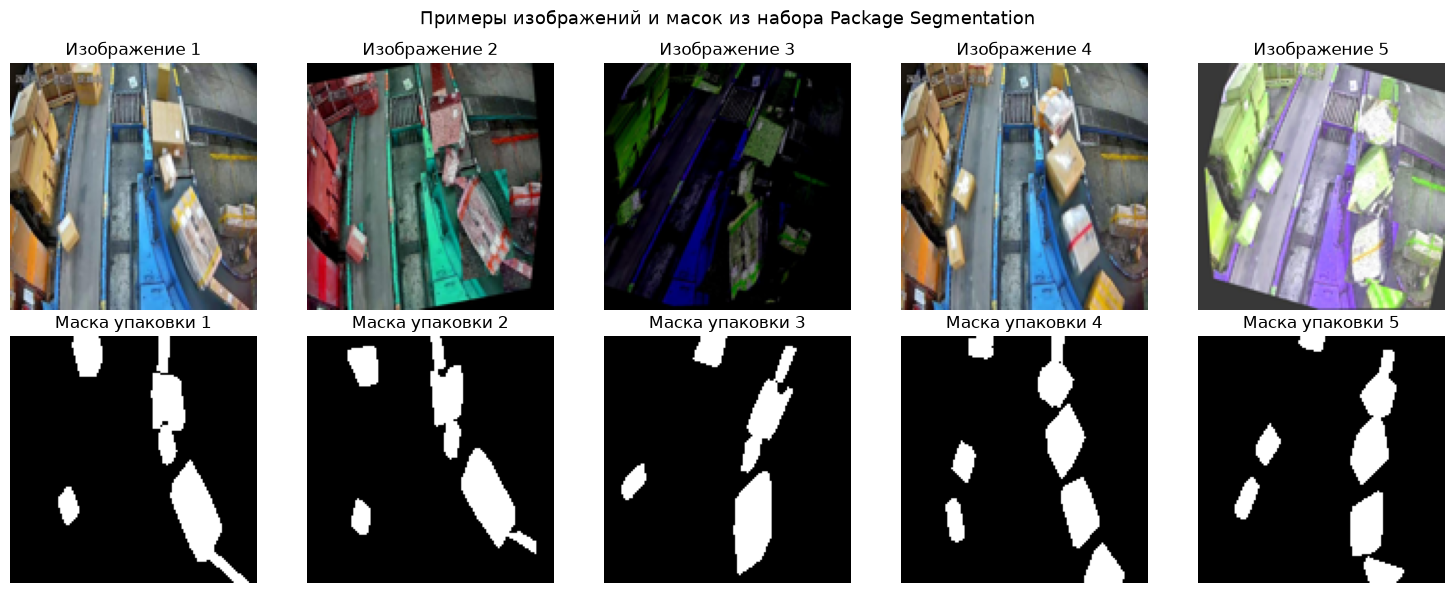

In [16]:
if train_dataset is not None and len(train_dataset) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for i in range(5):
        image, mask = train_dataset[i]
        axes[0, i].imshow(image.permute(1, 2, 0)); axes[0, i].set_title(f'Изображение {i+1}'); axes[0, i].axis('off')
        axes[1, i].imshow(mask[0], cmap='gray'); axes[1, i].set_title(f'Маска упаковки {i+1}'); axes[1, i].axis('off')
    plt.suptitle('Примеры изображений и масок из набора Package Segmentation', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 6. Облегчённая архитектура U-Net (PyTorch)

Архитектура полностью идентична использованной на занятии 6 (медицинская
сегментация), за исключением числа входных каналов (три вместо одного,
поскольку изображения упаковок цветные) -- иллюстрация переносимости
программного решения.

In [17]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)


class LightUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base_channels=16):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base_channels)
        self.enc2 = DoubleConv(base_channels, base_channels * 2)
        self.enc3 = DoubleConv(base_channels * 2, base_channels * 4)
        self.enc4 = DoubleConv(base_channels * 4, base_channels * 8)
        self.pool = nn.MaxPool2d(2, 2)

        self.upconv3 = nn.ConvTranspose2d(base_channels * 8, base_channels * 4, 2, stride=2)
        self.dec3 = DoubleConv(base_channels * 8, base_channels * 4)
        self.upconv2 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, 2, stride=2)
        self.dec2 = DoubleConv(base_channels * 4, base_channels * 2)
        self.upconv1 = nn.ConvTranspose2d(base_channels * 2, base_channels, 2, stride=2)
        self.dec1 = DoubleConv(base_channels * 2, base_channels)

        self.final_conv = nn.Conv2d(base_channels, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        d3 = self.dec3(torch.cat([self.upconv3(e4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.upconv2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.upconv1(d2), e1], dim=1))
        return self.final_conv(d1)


model = LightUNet(in_channels=3, out_channels=1, base_channels=16).to(device)
num_params = sum(p.numel() for p in model.parameters())
print(f'Число обучаемых параметров модели: {num_params:,}')

Число обучаемых параметров модели: 483,441


---
## Шаг 7. Функции потерь и метрики

In [18]:
def dice_coefficient(pred_probs, target, epsilon=1e-6):
    pred_binary = (pred_probs > 0.5).float()
    intersection = (pred_binary * target).sum(dim=(1, 2, 3))
    union_sum = pred_binary.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return ((2.0 * intersection + epsilon) / (union_sum + epsilon)).mean().item()


def iou_score(pred_probs, target, epsilon=1e-6):
    pred_binary = (pred_probs > 0.5).float()
    intersection = (pred_binary * target).sum(dim=(1, 2, 3))
    union = pred_binary.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) - intersection
    return ((intersection + epsilon) / (union + epsilon)).mean().item()


def dice_loss(pred_logits, target, epsilon=1e-6):
    pred_probs = torch.sigmoid(pred_logits)
    intersection = (pred_probs * target).sum(dim=(1, 2, 3))
    union_sum = pred_probs.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return 1.0 - ((2.0 * intersection + epsilon) / (union_sum + epsilon)).mean()


def combined_loss(pred_logits, target):
    return F.binary_cross_entropy_with_logits(pred_logits, target) + dice_loss(pred_logits, target)


print('Функции dice_coefficient, iou_score, dice_loss, combined_loss определены.')

Функции dice_coefficient, iou_score, dice_loss, combined_loss определены.


---
## Шаг 8. Цикл обучения

In [19]:
import time

if train_dataset is not None and len(train_dataset) > 0:
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    NUM_EPOCHS = 15
    history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_iou': []}
    t_start = time.time()

    for epoch in range(NUM_EPOCHS):
        model.train()
        train_loss_sum = 0.0
        for images, masks in train_loader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = combined_loss(logits, masks)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        train_loss = train_loss_sum / len(train_dataset)

        model.eval()
        val_loss_sum, dice_sum, iou_sum, n_batches = 0.0, 0.0, 0.0, 0
        with torch.no_grad():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)
                logits = model(images)
                loss = combined_loss(logits, masks)
                val_loss_sum += loss.item() * images.size(0)
                probs = torch.sigmoid(logits)
                dice_sum += dice_coefficient(probs, masks)
                iou_sum += iou_score(probs, masks)
                n_batches += 1

        val_loss = val_loss_sum / len(val_dataset)
        val_dice = dice_sum / n_batches
        val_iou = iou_sum / n_batches

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)
        history['val_iou'].append(val_iou)

        print(f'Эпоха {epoch+1:2d}/{NUM_EPOCHS} | потери(обуч.)={train_loss:.4f} | '
              f'потери(провер.)={val_loss:.4f} | Dice={val_dice:.4f} | IoU={val_iou:.4f}')

    print(f'\nВремя обучения: {time.time() - t_start:.1f} секунд (центральный процессор)')

Эпоха  1/15 | потери(обуч.)=1.5869 | потери(провер.)=1.5711 | Dice=0.2057 | IoU=0.1182
Эпоха  2/15 | потери(обуч.)=1.4373 | потери(провер.)=1.4162 | Dice=0.5012 | IoU=0.3555
Эпоха  3/15 | потери(обуч.)=1.3789 | потери(провер.)=1.2867 | Dice=0.5537 | IoU=0.4127
Эпоха  4/15 | потери(обуч.)=1.3243 | потери(провер.)=1.2816 | Dice=0.5991 | IoU=0.4584
Эпоха  5/15 | потери(обуч.)=1.2680 | потери(провер.)=1.2321 | Dice=0.5680 | IoU=0.4322
Эпоха  6/15 | потери(обуч.)=1.2235 | потери(провер.)=1.1483 | Dice=0.6364 | IoU=0.5015
Эпоха  7/15 | потери(обуч.)=1.1763 | потери(провер.)=1.1499 | Dice=0.6228 | IoU=0.4799
Эпоха  8/15 | потери(обуч.)=1.1278 | потери(провер.)=1.0923 | Dice=0.6205 | IoU=0.4810
Эпоха  9/15 | потери(обуч.)=1.0791 | потери(провер.)=1.0194 | Dice=0.6544 | IoU=0.5223
Эпоха 10/15 | потери(обуч.)=1.0325 | потери(провер.)=1.0435 | Dice=0.5647 | IoU=0.4233
Эпоха 11/15 | потери(обуч.)=0.9889 | потери(провер.)=0.9690 | Dice=0.6241 | IoU=0.4835
Эпоха 12/15 | потери(обуч.)=0.9413 | потери

80/20 - Эпоха 15/15 | потери(обуч.)=0.8177 | потери(провер.)=0.8633 | Dice=0.6582 | IoU=0.5134 
Время обучения: 61.6 секунд (центральный процессор)

130/40 Эпоха 14/15 | потери(обуч.)=0.8478 | потери(провер.)=0.7825 | Dice=0.7159 | IoU=0.5869
Эпоха 15/15 | потери(обуч.)=0.8059 | потери(провер.)=0.7965 | Dice=0.6281 | IoU=0.4902
Время обучения: 102.4 секунд (центральный процессор)

---
## Шаг 9. Визуализация кривых обучения

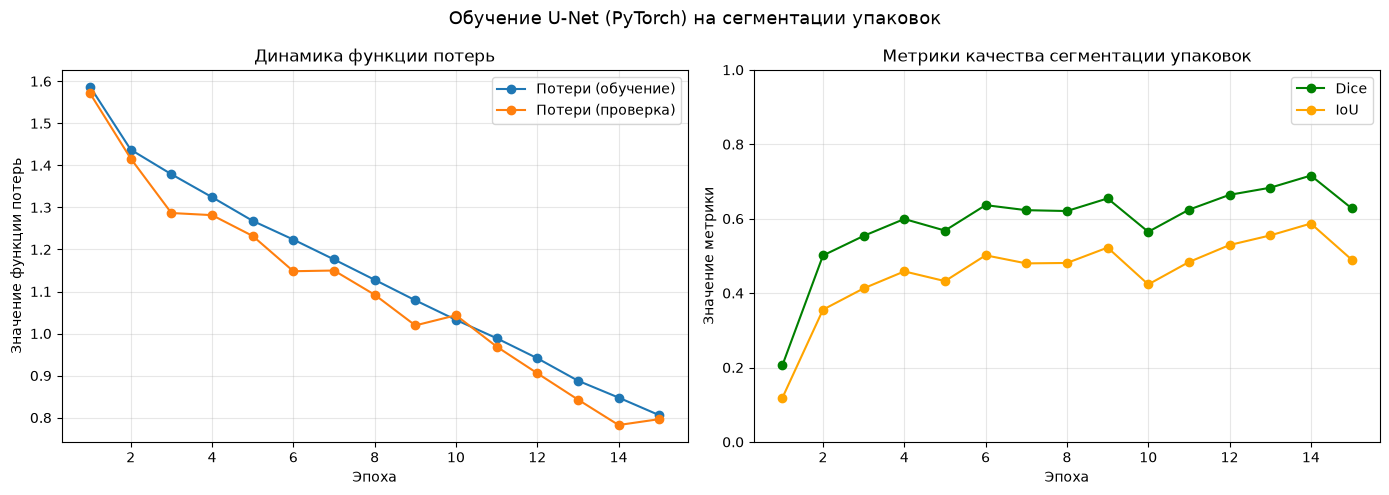

In [20]:
if train_dataset is not None and len(train_dataset) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    epochs_range = range(1, NUM_EPOCHS + 1)

    axes[0].plot(epochs_range, history['train_loss'], label='Потери (обучение)', marker='o')
    axes[0].plot(epochs_range, history['val_loss'], label='Потери (проверка)', marker='o')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Значение функции потерь')
    axes[0].set_title('Динамика функции потерь'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs_range, history['val_dice'], label='Dice', marker='o', color='green')
    axes[1].plot(epochs_range, history['val_iou'], label='IoU', marker='o', color='orange')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Значение метрики')
    axes[1].set_title('Метрики качества сегментации упаковок'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0, 1)

    plt.suptitle('Обучение U-Net (PyTorch) на сегментации упаковок', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 10. Визуальное сравнение результатов

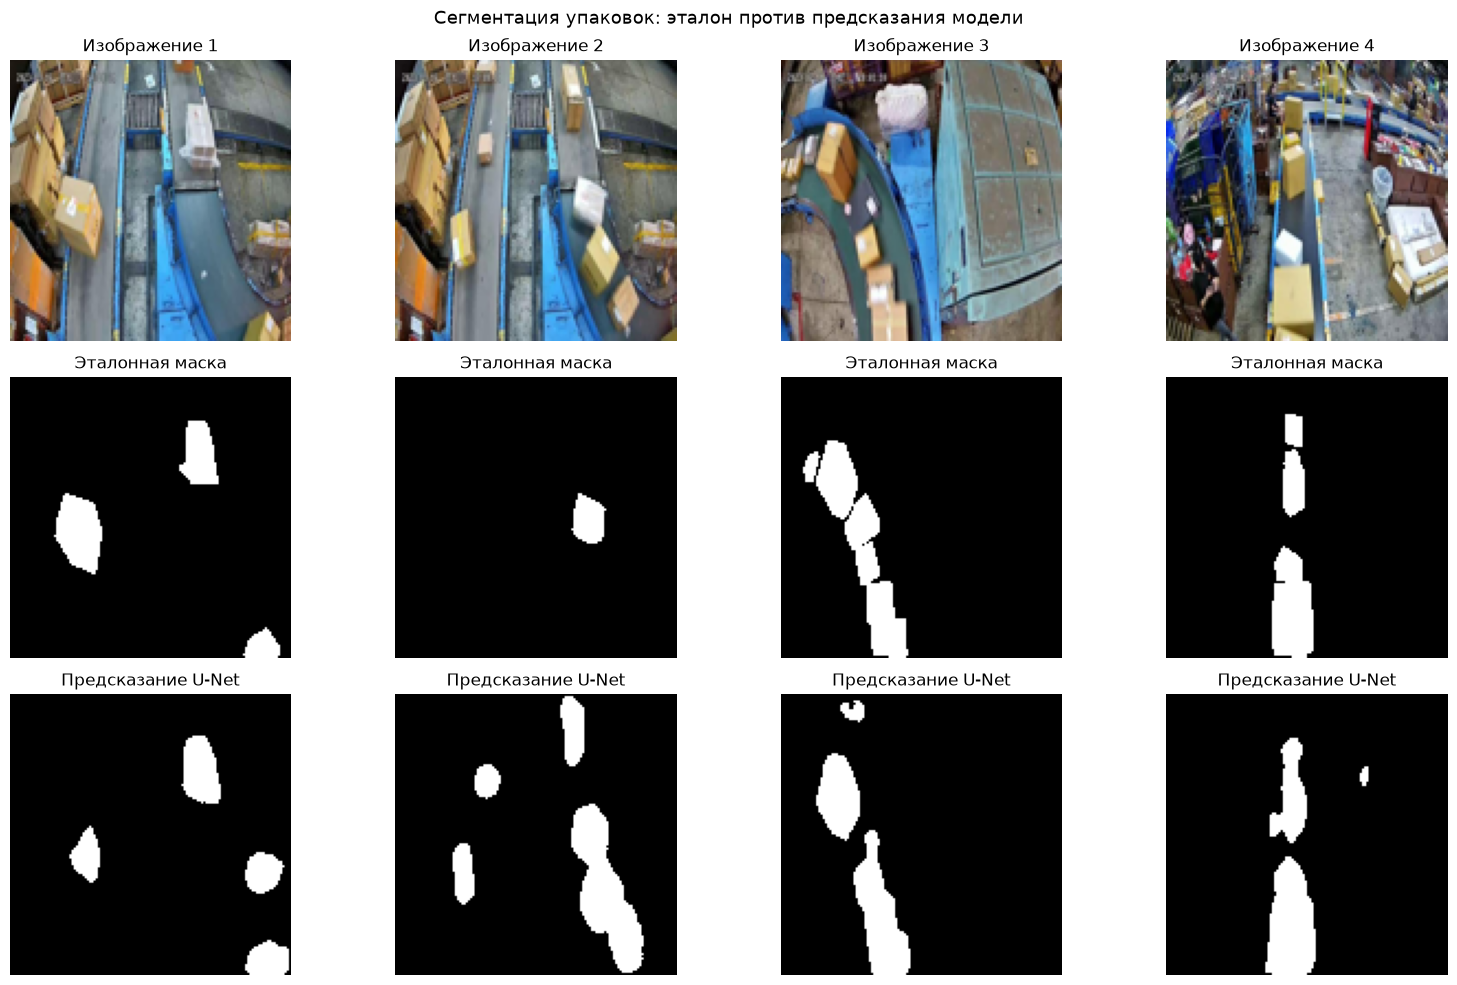

In [21]:
if train_dataset is not None and len(train_dataset) > 0:
    model.eval()
    num_show = 4
    fig, axes = plt.subplots(3, num_show, figsize=(4 * num_show, 10))

    for i in range(num_show):
        image, mask = val_dataset[i]
        with torch.no_grad():
            logits = model(image.unsqueeze(0).to(device))
            pred = (torch.sigmoid(logits)[0, 0].numpy() > 0.5).astype(np.float32)

        axes[0, i].imshow(image.permute(1, 2, 0)); axes[0, i].set_title(f'Изображение {i+1}'); axes[0, i].axis('off')
        axes[1, i].imshow(mask[0], cmap='gray'); axes[1, i].set_title('Эталонная маска'); axes[1, i].axis('off')
        axes[2, i].imshow(pred, cmap='gray'); axes[2, i].set_title('Предсказание U-Net'); axes[2, i].axis('off')

    plt.suptitle('Сегментация упаковок: эталон против предсказания модели', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 11. Обсуждение: семантическая сегментация против сегментации отдельных экземпляров

Найдём среди подвыборки изображение с несколькими упаковками рядом и обсудим,
что изменилось бы, если бы задача формулировалась как instance-сегментация.

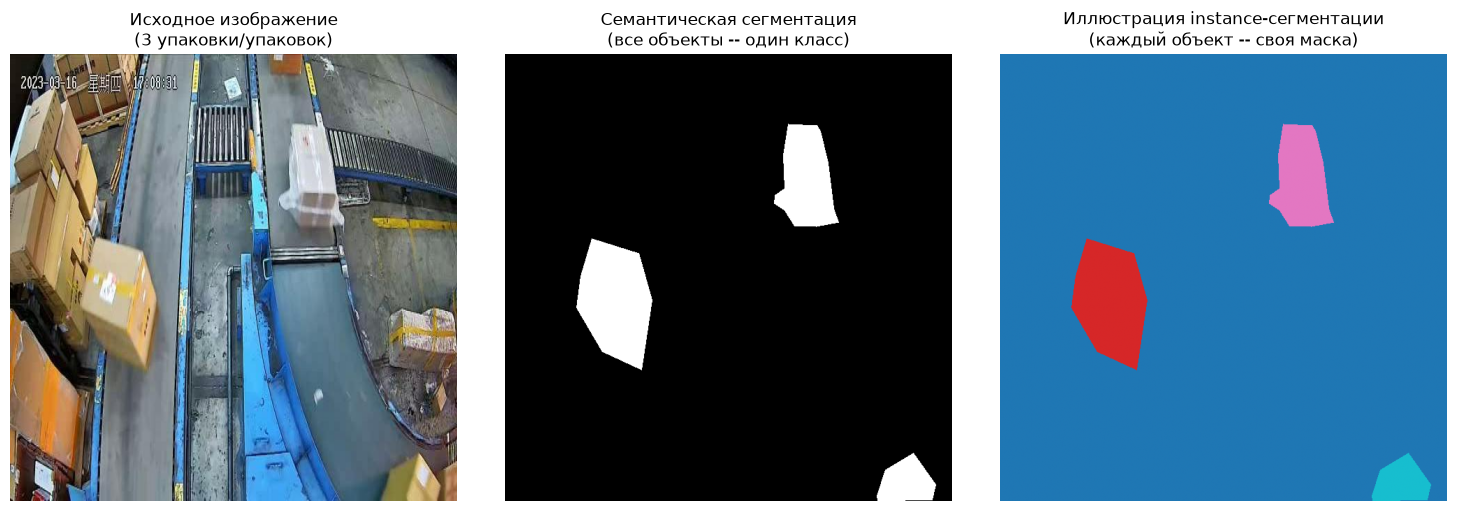

На изображении присутствует 3 упаковки/упаковок.
Семантическая сегментация не различает их между собой -- одна общая область.
Instance-сегментация (иллюстрация справа) дала бы отдельную маску для каждой упаковки,
что необходимо, например, для подсчёта числа упаковок или планирования захвата
конкретного объекта роботом-манипулятором.


In [22]:
if train_dataset is not None and len(train_dataset) > 0:
    # Ищем изображение с несколькими контурами (несколько упаковок) для иллюстрации
    multi_object_example = None
    for stem in val_stems:
        anno_path = LABEL_DIR_VAL / f'{stem}.txt'
        polygons = parse_yolo_seg_annotation(anno_path)
        if len(polygons) >= 2:
            multi_object_example = stem
            break

    if multi_object_example:
        img_path = IMG_DIR_VAL / f'{multi_object_example}.jpg'
        anno_path = LABEL_DIR_VAL / f'{multi_object_example}.txt'
        image = Image.open(img_path).convert('RGB')
        polygons = parse_yolo_seg_annotation(anno_path)

        semantic_mask = build_object_mask(image.size, polygons)

        # Иллюстрация instance-сегментации: каждому контуру -- собственный номер (цвет)
        instance_mask = np.zeros(image.size[::-1], dtype=np.int32)
        for obj_id, polygon in enumerate(polygons, start=1):
            single_mask = build_object_mask(image.size, [polygon])
            instance_mask[single_mask > 0] = obj_id

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(image); axes[0].set_title(f'Исходное изображение\n({len(polygons)} упаковки/упаковок)'); axes[0].axis('off')
        axes[1].imshow(semantic_mask, cmap='gray'); axes[1].set_title('Семантическая сегментация\n(все объекты -- один класс)'); axes[1].axis('off')
        axes[2].imshow(instance_mask, cmap='tab10'); axes[2].set_title('Иллюстрация instance-сегментации\n(каждый объект -- своя маска)'); axes[2].axis('off')
        plt.tight_layout()
        plt.show()

        print(f'На изображении присутствует {len(polygons)} упаковки/упаковок.')
        print('Семантическая сегментация не различает их между собой -- одна общая область.')
        print('Instance-сегментация (иллюстрация справа) дала бы отдельную маску для каждой упаковки,')
        print('что необходимо, например, для подсчёта числа упаковок или планирования захвата')
        print('конкретного объекта роботом-манипулятором.')
    else:
        print('В проверочной подвыборке не найдено изображений с несколькими объектами.')
        print('Попробуйте увеличить объём подвыборки или выбрать другие файлы.')

---
## Итоговая сводка

| Компонент | Реализация в ноутбуке |
|---|---|
| Набор данных | Package Segmentation (Ultralytics), подвыборка 80/20 изображений |
| Формат разметки | Контуры YOLO-сегментации -> бинарная маска |
| Библиотека | PyTorch |
| Архитектура | U-Net, 4 уровня, базовое число каналов 16, 3 входных канала |
| Функция потерь | Комбинация бинарной кросс-энтропии и функции потерь Дайса |
| Метрики | Коэффициент подобия Дайса, мера IoU |
| Обсуждение | Иллюстрация семантической vs instance-сегментации на реальном примере |

---
## Домашнее задание

1. **Основное.** Проведите отдельный эксперимент, увеличив число упаковок,
   расположенных рядом друг с другом (отфильтруйте изображения с 3+ объектами),
   и посчитайте Dice/IoU отдельно для этой подгруппы по сравнению с изображениями,
   содержащими одну упаковку.

2. **Сравнение с занятием 6.** Сопоставьте итоговые значения Dice/IoU,
   полученные в этом занятии (упаковки), с результатами занятия 6 (лёгкие на
   рентгеновских снимках) при одинаковом числе эпох и одинаковом объёме
   обучающей подвыборки. Предложите не менее двух гипотез, объясняющих
   расхождение в значениях метрик.

3. **Письменное задание.** Опишите (в 1-2 абзацах) гипотетический сценарий
   промышленного применения, где принципиально необходима instance-сегментация,
   а не семантическая, и обоснуйте выбор со ссылкой на конкретную операцию
   (сортировка, захват, подсчёт).

4. **(Дополнительно)** Изучите документацию по архитектуре Mask R-CNN
   (см. библиотеку torchvision, класс `maskrcnn_resnet50_fpn`) и составьте
   краткое сравнение (таблицу) её структуры с архитектурой U-Net, использованной
   в ноутбуке, не выполняя полного обучения модели.

5. **(Дополнительно)** Реализуйте функцию, вычисляющую отдельно значение Dice
   для каждой упаковки на изображениях с несколькими объектами (по аналогии
   с построением instance_mask в Шаге 11), и сравните с общим значением Dice,
   вычисленным для всего изображения целиком.